Importing Required Modules

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
from sklearn.cluster import KMeans

Defining position of robots and random points

In [2]:
robots = np.array([(8,0),(16,0),(23,0)])

In [ ]:
grid_size=30
while True:
    x = random.randint(0, grid_size - 1)
    y = random.randint(0, grid_size - 1)
    points = [x, y]
    if point not in points:
        points.append(point)
    if len(points) == 12:
        break

In [ ]:
points = np.array(points)

Applying Clustering

In [ ]:
kmeans = KMeans(n_clusters=3, init=robots)
kmeans.fit(points)
labels = kmeans.labels_

Indicating Clusters with different clusters

In [ ]:
for i in range(3):
    clusters = {i: points[labels == i]}

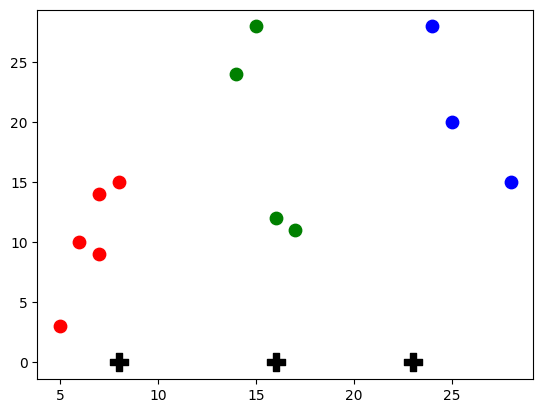

In [ ]:
colors = ['red', 'green', 'blue']
for i in range(12):
    x, y = points[i]
    plt.scatter(x, y, color=colors[labels[i]], s=80)

plt.scatter(8, 0, color='black', marker='P', s=150)
plt.scatter(16, 0, color='black', marker='P', s=150)
plt.scatter(23, 0, color='black', marker='P', s=150)

plt.show()

Calculating Distance with Nearest Neighbor(Nearest Unvisited Goal) Approach


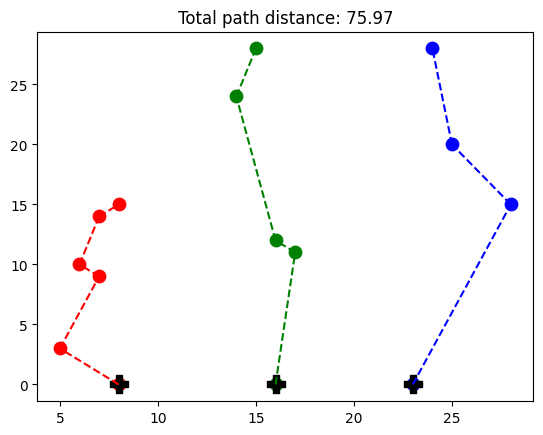

In [ ]:
distance = 0
for i in range(3):
    cluster_points = []
    for j in range(len(points)):
        if labels[j] == i:
            cluster_points.append(points[j])

    current = start_points[i]
    visited = [False] * len(cluster_points)
    path = [current]

    while not all(visited):
        nearest = None
        min_dist = float('inf')
        for k in range(len(cluster_points)):
            if not visited[k]:
                dist = math.dist(current, cluster_points[k])
                if dist < min_dist:
                    min_dist = dist
                    nearest = k
        distance += min_dist
        current = cluster_points[nearest]
        visited[nearest] = True
        path.append(current)

    for j in range(len(path) - 1):
        x1, y1 = path[j]
        x2, y2 = path[j + 1]
        plt.plot([x1, x2], [y1, y2], color=colors[i], linestyle='--')

    for x, y in path:
        plt.scatter(x, y, color=colors[i], s=80)

for sx, sy in start_points:
    plt.scatter(sx, sy, color='black', marker='P', s=150)

plt.title(f"Total path distance: {distance:.2f}")
plt.show()